In [1]:
import json

with open("data/IDS_hg38_region.json") as f:
    region = json.load(f)

seq = region["dna"].upper()

print(len(seq))

25500


In [2]:
import csv

variants = []
with open("results/editable_variants.csv") as f:
    for row in csv.DictReader(f):
        variants.append(row)

print(len(variants))

85


In [3]:
print(variants[0])

{'name': 'NM_000202.8(IDS):c.1591C>T (p.Gln531Ter)', 'pos': '149482807', 'ref_clinvar': 'G', 'alt_clinvar': 'A', 'base_genome': 'G', 'match': 'True', 'editor': 'ABE', 'edit_strand': '+'}


In [4]:
for variant in variants:
    variant["pos"] = int(variant["pos"])

print(variants[0]["pos"])

149482807


In [5]:
complement = {"A": "T", "T": "A", "C": "G", "G": "C"}

def reverse_complement(text):
    result = ""
    for letter in text:
        result = complement[letter] + result
    return result

print(reverse_complement("AACG"))

CGTT


In [6]:
rc = reverse_complement(seq)

print(len(rc))
print(reverse_complement(rc) == seq)

25500
True


In [7]:
allowed = {
    "A": "A",
    "C": "C",
    "G": "G",
    "T": "T",
    "R": "AG",
    "N": "ACGT",
}

def pam_matches(piece, pattern):
    if len(piece) != len(pattern):
        return False
    for i in range(len(pattern)):
        letter = piece[i]
        code = pattern[i]
        if letter not in allowed[code]:
            return False
    return True

print(pam_matches("AGG", "NGG"))
print(pam_matches("AGA", "NGG"))
print(pam_matches("AAG", "NRN"))
print(pam_matches("ACG", "NRN"))

True
False
True
False


In [8]:
REGION_START = 149481000

def target_index(variant):
    i = variant["pos"] - REGION_START
    if variant["edit_strand"] == "+":
        return i
    else:
        return len(seq) - 1 - i

print(target_index(variants[0]))

1807


In [9]:
def strand_sequence(variant):
    if variant["edit_strand"] == "+":
        return seq
    else:
        return rc

v = variants[0]
s = strand_sequence(v)
t = target_index(v)

print(v["ref_clinvar"], s[t])

G G


In [10]:
same = 0

for variant in variants:
    s = strand_sequence(variant)
    t = target_index(variant)
    found = s[t]

    if variant["edit_strand"] == "+":
        expected = variant["ref_clinvar"]
    else:
        expected = complement[variant["ref_clinvar"]]

    if found == expected:
        same = same + 1
    else:
        print("MISMATCH:", variant["name"], found, expected)

print(same, "of", len(variants), "agree")

85 of 85 agree


In [11]:
PROTOSPACER_LENGTH = 20
WINDOW_POSITIONS = [4, 5, 6, 7, 8]

def find_guides(variant, pam_pattern):
    s = strand_sequence(variant)
    t = target_index(variant)

    guides = []
    for p in WINDOW_POSITIONS:
        start = t - (p - 1)
        if start < 0:
            continue

        pam_start = start + PROTOSPACER_LENGTH
        pam_end = pam_start + len(pam_pattern)
        if pam_end > len(s):
            continue

        protospacer = s[start:pam_start]
        pam = s[pam_start:pam_end]

        if pam_matches(pam, pam_pattern):
            guides.append({
                "window_position": p,
                "protospacer": protospacer,
                "pam": pam,
            })

    return guides

found = find_guides(variants[0], "NGG")
print(len(found))

0


In [12]:
PAM_LIST = ["NGG", "NG", "NRN", "NNN"]

for pam_pattern in PAM_LIST:
    with_guide = 0
    for variant in variants:
        guides = find_guides(variant, pam_pattern)
        if len(guides) > 0:
            with_guide = with_guide + 1
    print(pam_pattern, with_guide)

NGG 22
NG 66
NRN 79
NNN 85


In [13]:
def bystander_positions(variant, guide):
    if variant["editor"] == "ABE":
        target_base = "A"
    else:
        target_base = "C"

    positions = []
    for p in WINDOW_POSITIONS:
        if p == guide["window_position"]:
            continue
        if guide["protospacer"][p - 1] == target_base:
            positions.append(p)
    return positions

In [14]:
v = variants[0]
guides = find_guides(v, "NNN")
g = guides[0]

print(v["name"])
print(g["protospacer"])
print("target position:", g["window_position"])
print("bystanders     :", bystander_positions(v, g))

NM_000202.8(IDS):c.1591C>T (p.Gln531Ter)
CCTGCAATGGGTCAGAATCC
target position: 4
bystanders     : [6, 7]


In [15]:
for pam_pattern in PAM_LIST:
    clean = 0
    for variant in variants:
        guides = find_guides(variant, pam_pattern)

        has_clean = False
        for guide in guides:
            if len(bystander_positions(variant, guide)) == 0:
                has_clean = True

        if has_clean:
            clean = clean + 1

    print(pam_pattern, clean)

NGG 5
NG 20
NRN 34
NNN 52


In [16]:
def cdna_position(name):
    start = name.find("c.") + 2
    number = ""
    for character in name[start:]:
        if character.isdigit():
            number = number + character
        elif character == "+" or character == "-":
            return None
        else:
            break
    return int(number)

print(cdna_position("NM_000202.8(IDS):c.1591C>T (p.Gln531Ter)"))
print(cdna_position("NM_000202.8(IDS):c.104-2A>G"))

1591
None


In [17]:
for variant in variants:
    variant["c_pos"] = cdna_position(variant["name"])

intronic = 0
for variant in variants:
    if variant["c_pos"] is None:
        intronic = intronic + 1

print("intronic targets:", intronic)
print("total variants  :", len(variants))

intronic targets: 11
total variants  : 85


In [18]:
def cdna_position_of(variant, guide, p):
    offset = p - guide["window_position"]
    if variant["edit_strand"] == "-":
        return variant["c_pos"] + offset
    else:
        return variant["c_pos"] - offset

print(cdna_position_of(v, g, 4))
print(cdna_position_of(v, g, 5))
print(cdna_position_of(v, g, 6))

1591
1590
1589


In [19]:
def protospacer_position(variant, guide, c):
    offset = c - variant["c_pos"]
    if variant["edit_strand"] == "-":
        return guide["window_position"] + offset
    else:
        return guide["window_position"] - offset

print(protospacer_position(v, g, 1591))
print(protospacer_position(v, g, 1590))
print(protospacer_position(v, g, 1589))

4
5
6


In [20]:
def coding_base(variant, guide, p):
    base = guide["protospacer"][p - 1]
    if variant["edit_strand"] == "-":
        return base
    else:
        return complement[base]

print(coding_base(v, g, 4))

C


In [21]:
def read_codon(variant, guide, codon_number):
    first = 3 * codon_number - 2
    codon = ""
    for c in [first, first + 1, first + 2]:
        p = protospacer_position(variant, guide, c)
        if p < 1 or p > 20:
            return None
        codon = codon + coding_base(variant, guide, p)
    return codon

print(read_codon(v, g, 531))

CAG


In [22]:
codon_table = {
    "TTT": "Phe", "TTC": "Phe", "TTA": "Leu", "TTG": "Leu",
    "TCT": "Ser", "TCC": "Ser", "TCA": "Ser", "TCG": "Ser",
    "TAT": "Tyr", "TAC": "Tyr", "TAA": "Ter", "TAG": "Ter",
    "TGT": "Cys", "TGC": "Cys", "TGA": "Ter", "TGG": "Trp",
    "CTT": "Leu", "CTC": "Leu", "CTA": "Leu", "CTG": "Leu",
    "CCT": "Pro", "CCC": "Pro", "CCA": "Pro", "CCG": "Pro",
    "CAT": "His", "CAC": "His", "CAA": "Gln", "CAG": "Gln",
    "CGT": "Arg", "CGC": "Arg", "CGA": "Arg", "CGG": "Arg",
    "ATT": "Ile", "ATC": "Ile", "ATA": "Ile", "ATG": "Met",
    "ACT": "Thr", "ACC": "Thr", "ACA": "Thr", "ACG": "Thr",
    "AAT": "Asn", "AAC": "Asn", "AAA": "Lys", "AAG": "Lys",
    "AGT": "Ser", "AGC": "Ser", "AGA": "Arg", "AGG": "Arg",
    "GTT": "Val", "GTC": "Val", "GTA": "Val", "GTG": "Val",
    "GCT": "Ala", "GCC": "Ala", "GCA": "Ala", "GCG": "Ala",
    "GAT": "Asp", "GAC": "Asp", "GAA": "Glu", "GAG": "Glu",
    "GGT": "Gly", "GGC": "Gly", "GGA": "Gly", "GGG": "Gly",
}

print(codon_table["CAG"])

Gln


In [23]:
def coding_strand_edit(variant):
    if variant["editor"] == "ABE":
        if variant["edit_strand"] == "-":
            return "A", "G"
        else:
            return "T", "C"
    else:
        if variant["edit_strand"] == "-":
            return "C", "T"
        else:
            return "G", "A"

print(coding_strand_edit(v))

('T', 'C')


In [24]:
def guide_verdict(variant, guide):
    positions = bystander_positions(variant, guide)

    if len(positions) == 0:
        return "clean"

    if variant["c_pos"] is None:
        return "unassessable"

    base_from, base_to = coding_strand_edit(variant)

    for p in positions:
        c = cdna_position_of(variant, guide, p)
        codon_number = (c + 2) // 3
        before = read_codon(variant, guide, codon_number)

        if before is None:
            return "unassessable"

        index = (c - 1) % 3

        if before[index] != base_from:
            return "unassessable"

        after = before[:index] + base_to + before[index + 1:]

        if codon_table[before] != codon_table[after]:
            return "changes_protein"

    return "clean"

print(guide_verdict(v, g))

changes_protein


In [25]:
pairs = []

for pam_pattern in PAM_LIST:
    for variant in variants:
        guides = find_guides(variant, pam_pattern)
        for guide in guides:
            pairs.append([pam_pattern, variant, guide])

print(len(pairs))

765


In [26]:
problems = 0

for pair in pairs:
    variant = pair[1]
    guide = pair[2]

    if variant["c_pos"] is None:
        continue

    base_from, base_to = coding_strand_edit(variant)

    for p in bystander_positions(variant, guide):
        c = cdna_position_of(variant, guide, p)
        codon_number = (c + 2) // 3
        before = read_codon(variant, guide, codon_number)

        if before is None:
            continue

        index = (c - 1) % 3

        if before[index] != base_from:
            problems = problems + 1
            print("PROBLEM:", variant["name"], "c." + str(c))

print("problems:", problems)

problems: 0


In [27]:
def protein_from_name(name):
    start = name.find("(p.")
    if start == -1:
        return None, None

    start = start + 3
    amino = name[start:start + 3]

    number = ""
    for character in name[start + 3:]:
        if character.isdigit():
            number = number + character
        else:
            break

    if number == "":
        return None, None

    return amino, int(number)

print(protein_from_name("NM_000202.8(IDS):c.1591C>T (p.Gln531Ter)"))
print(protein_from_name("NM_000202.8(IDS):c.104-2A>G"))

('Gln', 531)
(None, None)


In [28]:
agree = 0
disagree = 0

for pair in pairs:
    variant = pair[1]
    guide = pair[2]

    amino, number = protein_from_name(variant["name"])
    if amino is None:
        continue

    codon = read_codon(variant, guide, number)
    if codon is None:
        continue

    if codon_table[codon] == amino:
        agree = agree + 1
    else:
        disagree = disagree + 1
        print("MISMATCH:", variant["name"], codon, codon_table[codon], amino)

print("agree   :", agree)
print("disagree:", disagree)

agree   : 669
disagree: 0


In [29]:
summary = []

for pam_pattern in PAM_LIST:
    with_guide = 0
    strict = 0
    protein = 0
    unassessable = 0

    for variant in variants:
        guides = find_guides(variant, pam_pattern)
        if len(guides) == 0:
            continue

        with_guide = with_guide + 1

        has_strict = False
        has_clean = False
        has_unassessable = False

        for guide in guides:
            if len(bystander_positions(variant, guide)) == 0:
                has_strict = True

            verdict = guide_verdict(variant, guide)
            if verdict == "clean":
                has_clean = True
            if verdict == "unassessable":
                has_unassessable = True

        if has_strict:
            strict = strict + 1
        if has_clean:
            protein = protein + 1
        elif has_unassessable:
            unassessable = unassessable + 1

    summary.append([pam_pattern, with_guide, strict, protein, unassessable])

for row in summary:
    print(row)

['NGG', 22, 5, 10, 2]
['NG', 66, 20, 31, 6]
['NRN', 79, 34, 46, 5]
['NNN', 85, 52, 65, 5]


In [30]:
with open("results/pam_protein_summary.csv", "w") as f:
    f.write("pam,with_guide,strict_clean,protein_clean,unassessable\n")
    for row in summary:
        f.write(row[0] + "," + str(row[1]) + "," + str(row[2]) + "," + str(row[3]) + "," + str(row[4]) + "\n")

with open("results/pam_protein_summary.csv") as f:
    print(f.read())

pam,with_guide,strict_clean,protein_clean,unassessable
NGG,22,5,10,2
NG,66,20,31,6
NRN,79,34,46,5
NNN,85,52,65,5



In [31]:
labels = ["SpCas9 (NGG)", "SpG (NG)", "SpRY (NRN)", "no PAM (NNN)"]

strict_values = []
protein_values = []

for row in summary:
    strict_values.append(row[2])
    protein_values.append(row[3])

print(labels)
print(strict_values)
print(protein_values)

['SpCas9 (NGG)', 'SpG (NG)', 'SpRY (NRN)', 'no PAM (NNN)']
[5, 20, 34, 52]
[10, 31, 46, 65]


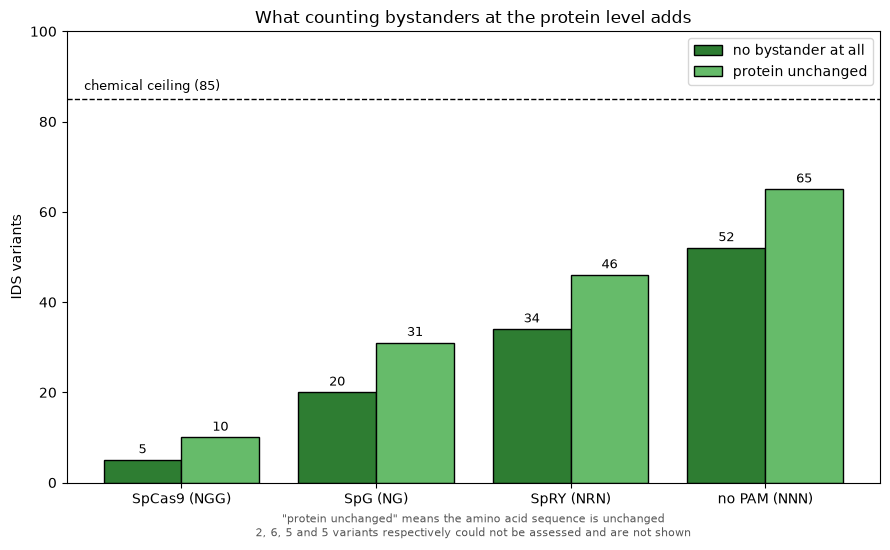

In [32]:
import matplotlib.pyplot as plt

left = [0.0, 1.0, 2.0, 3.0]
right = [0.4, 1.4, 2.4, 3.4]
middle = [0.2, 1.2, 2.2, 3.2]

fig, ax = plt.subplots(figsize=(9, 5.6))

ax.bar(left, strict_values, 0.4, color="#2E7D32", edgecolor="black", label="no bystander at all")
ax.bar(right, protein_values, 0.4, color="#66BB6A", edgecolor="black", label="protein unchanged")

for i in [0, 1, 2, 3]:
    ax.text(left[i], strict_values[i] + 1.5, str(strict_values[i]), ha="center", fontsize=9)
    ax.text(right[i], protein_values[i] + 1.5, str(protein_values[i]), ha="center", fontsize=9)

ax.axhline(85, color="black", linestyle="--", linewidth=1)
ax.text(-0.3, 87, "chemical ceiling (85)", fontsize=9)

ax.set_xticks(middle)
ax.set_xticklabels(labels)
ax.set_ylabel("IDS variants")
ax.set_title("What counting bystanders at the protein level adds")
ax.set_xlabel('"protein unchanged" means the amino acid sequence is unchanged\n2, 6, 5 and 5 variants respectively could not be assessed and are not shown',
              fontsize=8, color="#555555")
ax.set_ylim(0, 100)
ax.legend()

plt.tight_layout()
plt.savefig("results/fig7_protein.png", dpi=200)
plt.show()

## Part 2 — The anatomy of a bystander

Why are some bystanders harmless? Which variants can never be cleanly
edited, whatever the reagent?

In [33]:
def describe_bystander(variant, guide, p):
    base_from, base_to = coding_strand_edit(variant)

    c = cdna_position_of(variant, guide, p)
    codon_number = (c + 2) // 3
    before = read_codon(variant, guide, codon_number)

    if before is None:
        return None

    index = (c - 1) % 3
    after = before[:index] + base_to + before[index + 1:]

    if codon_table[before] == codon_table[after]:
        effect = "synonymous"
    elif codon_table[after] == "Ter":
        effect = "nonsense"
    else:
        effect = "missense"

    return [variant["editor"], index + 1, effect]

print(describe_bystander(v, g, 6))

['ABE', 2, 'missense']


In [34]:
bystander_records = []

for pair in pairs:
    if pair[0] != "NNN":
        continue

    variant = pair[1]
    guide = pair[2]

    if variant["c_pos"] is None:
        continue

    for p in bystander_positions(variant, guide):
        record = describe_bystander(variant, guide, p)
        if record is not None:
            bystander_records.append(record)

print(len(bystander_records))

396


In [35]:
position_counts = {1: 0, 2: 0, 3: 0}
synonymous_counts = {1: 0, 2: 0, 3: 0}

for record in bystander_records:
    position = record[1]
    effect = record[2]

    position_counts[position] = position_counts[position] + 1

    if effect == "synonymous":
        synonymous_counts[position] = synonymous_counts[position] + 1

for position in [1, 2, 3]:
    print(position, position_counts[position], synonymous_counts[position])

1 149 20
2 115 0
3 132 127


In [36]:
effect_counts = {"synonymous": 0, "missense": 0, "nonsense": 0}

for record in bystander_records:
    effect = record[2]
    effect_counts[effect] = effect_counts[effect] + 1

print(effect_counts)

{'synonymous': 147, 'missense': 239, 'nonsense': 10}


In [37]:
editor_effects = {}
editor_effects["ABE"] = {"synonymous": 0, "missense": 0, "nonsense": 0}
editor_effects["CBE"] = {"synonymous": 0, "missense": 0, "nonsense": 0}

for record in bystander_records:
    editor = record[0]
    effect = record[2]
    editor_effects[editor][effect] = editor_effects[editor][effect] + 1

print("ABE", editor_effects["ABE"])
print("CBE", editor_effects["CBE"])

ABE {'synonymous': 50, 'missense': 146, 'nonsense': 0}
CBE {'synonymous': 97, 'missense': 93, 'nonsense': 10}


In [38]:
editor_positions = {}
editor_positions["ABE"] = {1: 0, 2: 0, 3: 0}
editor_positions["CBE"] = {1: 0, 2: 0, 3: 0}

for record in bystander_records:
    editor = record[0]
    position = record[1]
    editor_positions[editor][position] = editor_positions[editor][position] + 1

print("ABE", editor_positions["ABE"])
print("CBE", editor_positions["CBE"])

ABE {1: 71, 2: 77, 3: 48}
CBE {1: 78, 2: 38, 3: 84}


In [39]:
hard_variants = []

for variant in variants:
    if variant["c_pos"] is None:
        continue

    guides = find_guides(variant, "NNN")
    if len(guides) == 0:
        continue

    has_clean = False
    for guide in guides:
        if guide_verdict(variant, guide) == "clean":
            has_clean = True

    if has_clean == False:
        hard_variants.append(variant)

print(len(hard_variants))

15


In [40]:
for variant in hard_variants:
    amino, number = protein_from_name(variant["name"])
    print(variant["editor"], number, amino, variant["name"])

ABE 491 Ser NM_000202.8(IDS):c.1472C>T (p.Ser491Phe)
ABE 475 Trp NM_000202.8(IDS):c.1425G>A (p.Trp475Ter)
ABE 475 Trp NM_000202.8(IDS):c.1424G>A (p.Trp475Ter)
ABE 443 Arg NM_000202.8(IDS):c.1327C>T (p.Arg443Ter)
ABE 434 Glu NM_000202.8(IDS):c.1300G>A (p.Glu434Lys)
CBE 135 Lys NM_000202.8(IDS):c.404A>G (p.Lys135Arg)
CBE 135 Lys NM_000202.8(IDS):c.403A>G (p.Lys135Glu)
CBE 110 Arg NM_000202.8(IDS):c.328A>G (p.Arg110Gly)
ABE 109 Trp NM_000202.8(IDS):c.327G>A (p.Trp109Ter)
ABE 109 Trp NM_000202.8(IDS):c.326G>A (p.Trp109Ter)
CBE 95 Arg NM_000202.8(IDS):c.283A>G (p.Arg95Gly)
CBE 92 Leu NM_000202.8(IDS):c.275T>C (p.Leu92Pro)
CBE 72 Leu NM_000202.8(IDS):c.215T>C (p.Leu72Pro)
ABE 46 Asp NM_000202.8(IDS):c.136G>A (p.Asp46Asn)
CBE 45 Asp NM_000202.8(IDS):c.134A>G (p.Asp45Gly)


In [41]:
def harmful_count(variant, guide):
    harmful = 0
    for p in bystander_positions(variant, guide):
        record = describe_bystander(variant, guide, p)
        if record is None:
            continue
        if record[2] != "synonymous":
            harmful = harmful + 1
    return harmful

print(harmful_count(v, g))

1


In [42]:
for variant in hard_variants:
    guides = find_guides(variant, "NNN")

    fewest = None
    for guide in guides:
        harmful = harmful_count(variant, guide)
        if fewest is None or harmful < fewest:
            fewest = harmful

    amino, number = protein_from_name(variant["name"])
    print(fewest, variant["editor"], number, amino, variant["name"])

1 ABE 491 Ser NM_000202.8(IDS):c.1472C>T (p.Ser491Phe)
1 ABE 475 Trp NM_000202.8(IDS):c.1425G>A (p.Trp475Ter)
1 ABE 475 Trp NM_000202.8(IDS):c.1424G>A (p.Trp475Ter)
1 ABE 443 Arg NM_000202.8(IDS):c.1327C>T (p.Arg443Ter)
1 ABE 434 Glu NM_000202.8(IDS):c.1300G>A (p.Glu434Lys)
1 CBE 135 Lys NM_000202.8(IDS):c.404A>G (p.Lys135Arg)
1 CBE 135 Lys NM_000202.8(IDS):c.403A>G (p.Lys135Glu)
2 CBE 110 Arg NM_000202.8(IDS):c.328A>G (p.Arg110Gly)
1 ABE 109 Trp NM_000202.8(IDS):c.327G>A (p.Trp109Ter)
1 ABE 109 Trp NM_000202.8(IDS):c.326G>A (p.Trp109Ter)
1 CBE 95 Arg NM_000202.8(IDS):c.283A>G (p.Arg95Gly)
1 CBE 92 Leu NM_000202.8(IDS):c.275T>C (p.Leu92Pro)
1 CBE 72 Leu NM_000202.8(IDS):c.215T>C (p.Leu72Pro)
1 ABE 46 Asp NM_000202.8(IDS):c.136G>A (p.Asp46Asn)
1 CBE 45 Asp NM_000202.8(IDS):c.134A>G (p.Asp45Gly)


In [43]:
WINDOWS = [[4, 5, 6, 7, 8], [4, 5, 6, 7], [4, 5, 6], [5, 6, 7]]

for window in WINDOWS:
    WINDOW_POSITIONS = window

    clean = 0
    unassessable = 0

    for variant in variants:
        guides = find_guides(variant, "NNN")
        if len(guides) == 0:
            continue

        has_clean = False
        has_unassessable = False

        for guide in guides:
            verdict = guide_verdict(variant, guide)
            if verdict == "clean":
                has_clean = True
            if verdict == "unassessable":
                has_unassessable = True

        if has_clean:
            clean = clean + 1
        elif has_unassessable:
            unassessable = unassessable + 1

    print(window, clean, unassessable)

WINDOW_POSITIONS = [4, 5, 6, 7, 8]

[4, 5, 6, 7, 8] 65 5
[4, 5, 6, 7] 72 5
[4, 5, 6] 77 3
[5, 6, 7] 77 3


In [44]:
for pam_pattern in PAM_LIST:
    clean = 0
    unassessable = 0

    for variant in variants:
        guides = find_guides(variant, pam_pattern)
        if len(guides) == 0:
            continue

        has_clean = False
        has_unassessable = False

        for guide in guides:
            verdict = guide_verdict(variant, guide)
            if verdict == "clean":
                has_clean = True
            if verdict == "unassessable":
                has_unassessable = True

        if has_clean:
            clean = clean + 1
        elif has_unassessable:
            unassessable = unassessable + 1

    print(pam_pattern, "clean:", clean, " unassessable:", unassessable)

NGG clean: 10  unassessable: 2
NG clean: 31  unassessable: 6
NRN clean: 46  unassessable: 5
NNN clean: 65  unassessable: 5


In [45]:
WINDOW_POSITIONS = [4, 5, 6]

for variant in variants:
    if variant["c_pos"] is None:
        continue

    guides = find_guides(variant, "NNN")
    if len(guides) == 0:
        continue

    has_clean = False
    for guide in guides:
        if guide_verdict(variant, guide) == "clean":
            has_clean = True

    if has_clean == False:
        amino, number = protein_from_name(variant["name"])
        print(variant["editor"], number, amino, variant["name"])

WINDOW_POSITIONS = [4, 5, 6, 7, 8]

CBE 110 Arg NM_000202.8(IDS):c.328A>G (p.Arg110Gly)
CBE 95 Arg NM_000202.8(IDS):c.283A>G (p.Arg95Gly)
CBE 72 Leu NM_000202.8(IDS):c.215T>C (p.Leu72Pro)
ABE 46 Asp NM_000202.8(IDS):c.136G>A (p.Asp46Asn)
CBE 45 Asp NM_000202.8(IDS):c.134A>G (p.Asp45Gly)
